# PCHN63112 Workshop 1: Introducing GLMs
In this week's lesson, we introduced all the elements needed for understanding the GLM framework. In this workshop, we will explore a number of these elements further using `R`. The aim is to provide greater intuition before we see our first applied example next week.

## Alternative Distributions in `R`
To begin, all common probability distribution are implemented inside `R` as functions that allow us to calculate various properties of the distribution. As well as this, there are functions that allow us to take a random sample from each distribution, providing a simulation of the data-generating process. 

### Standard Normal Example
As an example, the *height* of the standard normal curve at an $x$-value of 1.5 can be calculated using

In [1]:
dnorm(x=1.5, mean=0, sd=1)

[1] 0.1295176

giving the *density* of the distribution at the given point. The probability of an $x$-value of 1.5 can be calculated using

In [2]:
pnorm(q=1.5, mean=0, sd=1, lower.tail=FALSE)

[1] 0.0668072

This gives the area under the curve *above* the given point. The probability *below* the point can be returned by setting `lower.tail=TRUE`, which is the default. Converting a probability into an $x$-value is also possible using

In [3]:
qnorm(p=0.067, mean=0, sd=1, lower.tail=FALSE)

[1] 1.498513

which is known as the *quantile* function. This tells us that the $x$-value with an associated upper-tail probability of $p=0.67$ is $x=1.498513$.

As well as querying properties of the distribution, we can also generate a random sample of a given size from a standard normal distribution using

In [4]:
rnorm(n=10, mean=0, sd=1)

 [1]  0.1691176  1.0458620  0.3633340 -0.4965324  1.1933982 -0.3797968 -1.2668935  0.1337453 -0.4495531 -1.7171725

This is particularly useful for running simulations as a random sample taken from a known distribution is the starting point for many methods within parameteric statistics.

<div class="alert alert-block alert-success"><b>Exercise #1</b> 

Try using the <code>rnorm</code> function to generate date from two hypothetical experimental groups with different means and analyse them using <code>t.test</code>. This is a very simple example of running a <i>simulation</i> to validate an analysis.
</div>

### Plotting the Standard Normal
The density functions can also be used to *plot* a distribution, which can be helpful for understanding how a distribution will behave for different values of its parameters. When the distribution is continuous, the `curve` function is the simplest to use. For instance, to plot a standard normal distribution we can use

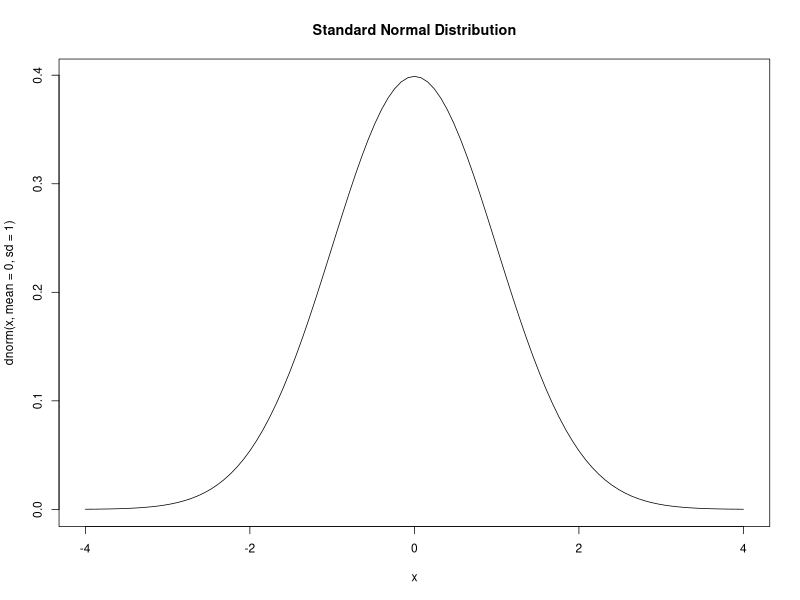

In [5]:
curve(dnorm(x,mean=0,sd=1), xlim=c(-4,4), main='Standard Normal Distribution')

Here, the `dnorm` function is provides as an argument, telling `curve` what to use to generate the $y$-axis values. Whatever we pass to `curve`, it needs to reference a variable called `x` that will be used internally by `curve` as a reference to the $x$-axis. We can then tell `curve` what range of $x$-values to use with the `xlim` argument. If this is omitted, `curve` will default to `xlim=c(0,1)` which, depending upon the distribution, might show nothing if the distribution sits outside this intervals.

<div class="alert alert-block alert-success"><b>Exercise #2</b> 

Have a play around with plotting different normal distributions by changing the values of <code>mean</code> and <code>sd</code>. Remember to change the <code>xlim</code> argument to something suitable, otherwise the distribution may only be partially visible, or not visible at all. 
</div>

### Alternative Distributions
Similar distribution functions exist in `R` for the binomial/Bernoulli distribution, Poisson distribution and gamma distribution. For instance, given a Poisson distribution with $\lambda = 3$

In [6]:
dpois(x=2, lambda=3)

[1] 0.2240418

In [7]:
ppois(q=2, lambda=3, lower.tail=FALSE)

[1] 0.5768099

In [8]:
qpois(p=0.6, lambda=3, lower.tail=FALSE)

[1] 2

We can also plot this distribution. However, because the Poisson is *discrete*, it's better to use `plot` with the `type="h"` argument. In order to do this, we provide a simple range of integers as the $x$-axis values, both for the `x=` argument and within the Poisson density function.

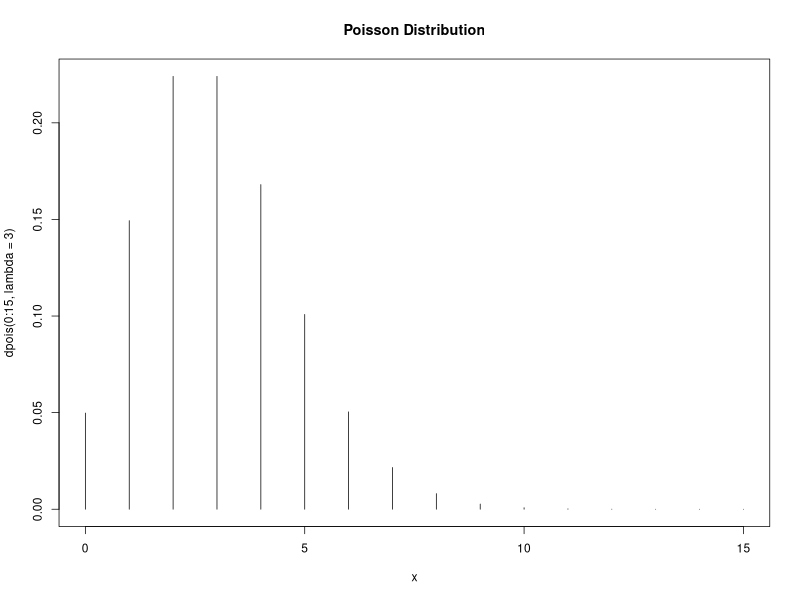

In [9]:
plot(x=0:15, xlab="x", y=dpois(0:15,lambda=3), type="h", main="Poisson Distribution")

<div class="alert alert-block alert-success"><b>Exercise #3</b> 

Try changing the value of <code>lambda</code> and see how it affects both the centre and the width of the Poisson distribution. Remember to adjust the generated range of <code>x</code> values so that the distribution is visible.
</div>

<div class="alert alert-block alert-success"><b>Exercise #4</b> 

Use the techniques above to try plotting a gamma distribution, starting with <code>dgamma(x, shape=2, scale=2)</code>. Remember, this is a <i>continuous</i> distribution, like the standard normal, that is defined only for positive numbers. Once plotted, you can try adjusting the parameter values to see how the shape of the distribution changes.
</div>

## The Exponential Family
One of the key ideas explored in this week's lesson was that GLMs are defined for any distribution from the *exponential family*, meaning that the distribution functions explored above can be written in the same generic form. Although this is only really important in terms of the underlying mathematics, it can be helpful to see this demonstrated in `R`. To do so, we can define the exponential form as a `function` in `R`. We can then adjust the arguments and compare the output to the built-in distribution functions. This will demonstrate how all these distributions can effectively be built *using the same recipe*, just with some adjustments to the ingredients. This lies at the heart of how GLMs are able to use the same framework to cover data from a variety of different distributions.

### Defining `dexponential_family`
To begin, we need to define the density function for a distribution from the exponential family. This is a simply case of writing the formula defined in the lesson within `R`. The function takes the data `y`, the two exponential parameters `theta` ($\theta$) and `phi` ($\phi$), and then the definition of the three functions `A()`, `B()` and `C()`. We define these as uppercase simply because defining `c()` would overwrite the concatenation function in `R` and cause a number of errors.

In [10]:
dexponential_family <- function(y,theta,phi,A,B,C){
  exp(((y*theta - B(theta))/A(phi)) + C(y,phi))
}

Once available in `R`, all we have to do is provide a value for `y`, `theta` and `phi`, as well as definitions of `A(phi)`, `B(theta)` and `C(y,theta)`. Depending on these choices, we can turn the `dexponential_family()` function into a variety of different distribution. 

### Normal Distribution From Exponential Form
Starting with the normal distribution, we can compare a visualisation created using the built-in distribution functions to a visualisation using the exponential form. Don't worry about where the definitions of all the elements of the exponential form come from. They don't matter. What matters is the conceptual point that we can, with specific choices for all these aspects, create the same normal distribution from a more generic formula.

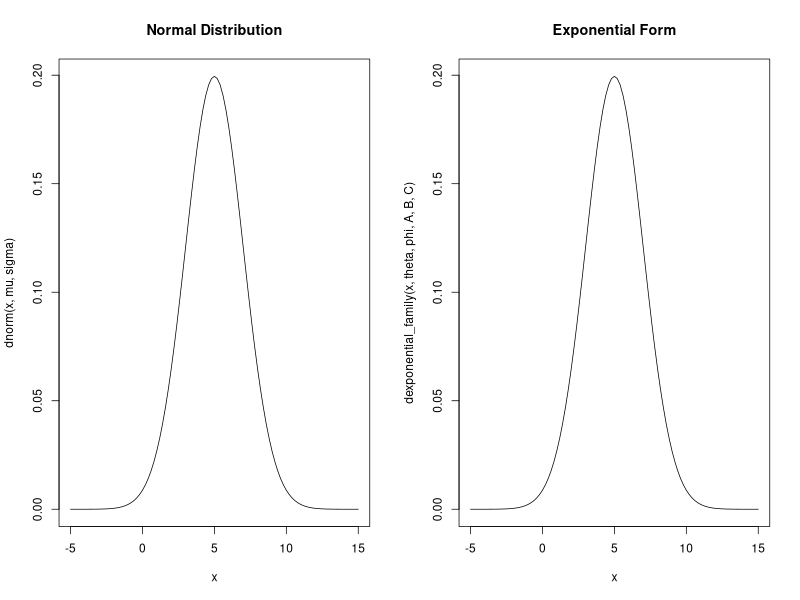

In [11]:
# Plot in 1 x 2 grid
par(mfrow=c(1,2))

#=====================#
# Original definition #
#=====================#
mu    <- 5
sigma <- 2

curve(dnorm(x,mu,sigma), xlim=c(-5,15), main='Normal Distribution')

#==================#
# Exponential form #
#==================#
A <- function(phi){   phi                            } 
B <- function(theta){ (theta^2)/2                    }
C <- function(y,phi){ -((y^2)/phi + log(2*pi*phi))/2 }

theta <- mu 
phi   <- sigma^2

curve(dexponential_family(x,theta,phi,A,B,C), xlim=c(-5,15), main='Exponential Form')

# Reset plotting
par(mfrow=c(1,1))

<div class="alert alert-block alert-success"><b>Exercise #5</b> 

Mess around with the definitions of <code>A</code> <code>B</code> and <code>C</code> in the code above and see how this breaks the correspondence with the normal distribution. Notice that this equivalence only works under very specific definitions of these functions.
</div>

### Poisson Distribution From Exponential Form
As a second example, we will see how the Poisson distribution can be generated using the same format. This is a useful example because the Poisson is quite different from the normal in several ways: the Poisson is *discrete*, the Poisson is *strictly positive*, and the Poisson mean and variance are *not independent* of each other. Despite these seemingly very distinct differences, we can generate a Poisson using a similar method

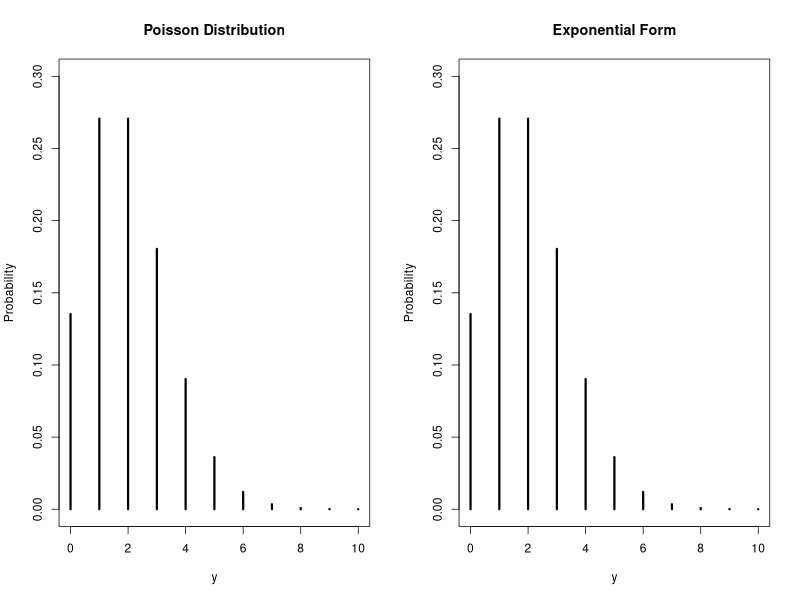

In [12]:
# Plot in 1 x 2 grid
par(mfrow=c(1,2))

#=====================#
# Original definition #
#=====================#
lambda <- 2

plot(0:10, dpois(0:10,lambda), type="h", lwd=3, ylim=c(0,0.3),
     main="Poisson Distribution", xlab="y", ylab="Probability")

#==================#
# Exponential form #
#==================#
A <- function(phi)   { 1                  }
B <- function(theta) { exp(theta)         }
C <- function(y,phi) { -log(factorial(y)) }

theta <- log(lambda)
phi   <- 1

plot(0:10, dexponential_family(0:10,theta,phi,A,B,C),
     type="h", lwd=3, ylim=c(0,0.3), main="Exponential Form",
     xlab="y", ylab="Probability")

# Reset plotting
par(mfrow=c(1,1))

Again, the two distributions are identical. This provides a direct demonstration of the principle at the heart of the GLM framework. If all these distributions can be defined in a similar way, they can be modelled and estimated using the same approach and thus multiple distributions of different types can be leveraged for analysing data. Although a common choice, the normal distribution is then just a *special case* of a more general-purpose framework.

## Asymptotic Inference
Another important aspect of this week's lesson was the concept of *asymptotic inference*. Under both the Wald and likelihood ratio frameworks, the null distribution of the test statistic is only known under a *large enough* sample. Unfortunately, the concept of "large enough" depends upon the data and so cannot be defined as a specific $n$. As such, we have to use $n$ as a rough index of our confidence in the results.

We can demonstrate these ideas using simulations. In particular, we can show how reliable or unreliable these approximations are when $n$ is small. The code below will run a simulation where samples of a given size are drawn from a Poisson distribution and then used to estimate the parameter $\lambda$. From these samples, the distribution of the Wald statistic under the null can be generated and then visualised against a standard normal distribution. The starting value is $n = 1000$, which should be large enough to approximate a normal distribution well, as shown in the plot below.

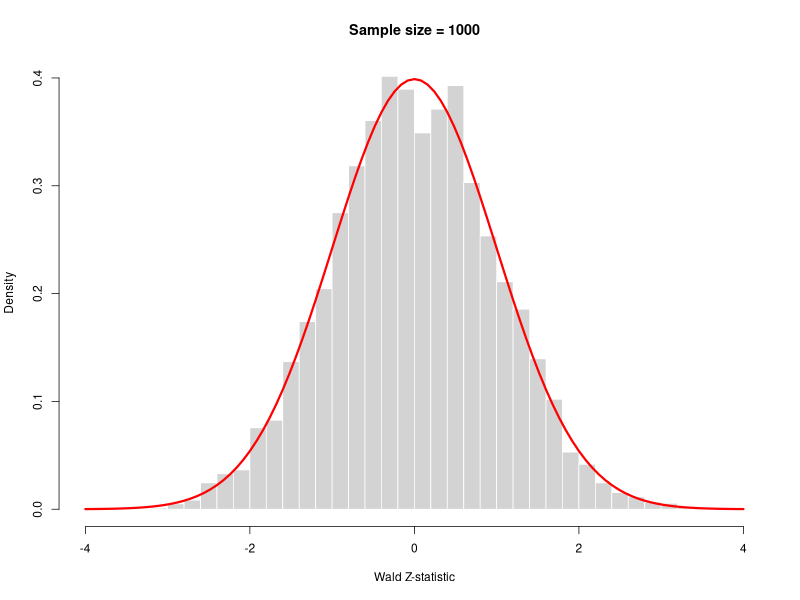

In [13]:
# Simulation Parameters
set.seed(666)
n      <- 1000
lambda <- 2
n.sim  <- 10000

# Simulate Wald Z-statistics (under the null)
wald <- replicate(n.sim, {

  # Sample from Poisson distribution
  y <- rpois(n, lambda)

  # Estimate lambda
  lambda.hat <- mean(y)

  # sqrt(W) 
  (lambda.hat - lambda) / sqrt(lambda.hat / n)
})

# Plot the distribution
hist(wald, 
     probability = TRUE, 
     breaks      = 50,
     col         = "lightgrey", 
     border      = "white",
     xlab        = "Wald Z-statistic",
     main        = paste("Sample size =",n),
     xlim        = c(-4,4))

# Add standard normal curve
curve(dnorm(x), 
      add = TRUE, 
      col = "red", 
      lwd = 3)


<div class="alert alert-block alert-success"><b>Exercise #6</b> 

Copy the code above into an <code>R</code> script and then try changing the value of <code>n</code> to different sizes. What happens to the accuracy of the distribution when <code>n <- 5</code> or <code>n <- 10</code>? At what point does the sample size seem large enough for the distribution to converge on a standard normal? 
</div>

<div class="alert alert-block alert-success"><b>Exercise #7</b> 

Try changing the value of <code>lambda</code> in the code above. Does the point where the distribution converges change? What does this tell you about the definition of a sample that is "large enough"?
</div>